In [3]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        """
        初始化多层感知机

        参数:
            input_size:  输入特征维度
            hidden_size: 隐藏层神经元数量
            output_size: 输出维度
        """
        super(MLP, self).__init__()
        # TODO: 定义全连接层和激活函数
        #实现一个全连接层
        self.fc1 = nn.Linear(input_size, hidden_size)      # 输入层 → 隐藏层
        self.fc2 = nn.Linear(hidden_size, output_size)      # 隐藏层 → 输出层
        self.relu = nn.ReLU()#隐藏层激活函数
        self.sigmoid = nn.Sigmoid()#输出层激活函数-->二分类任务？

    def forward(self, x):
        """
        前向传播

        参数:
            x: 输入数据，形状为 (batch_size, input_size)

        返回:
            输出值，形状为 (batch_size, output_size)
        """
        # TODO: 补全前向传播过程
        x = self.relu(self.fc1(x))              # fc1 + relu
        x = self.sigmoid(self.fc2(x))              # fc2 + sigmoid
        return x

In [4]:
def generate_moon_data(n_samples=1000, noise=0.15, test_size=0.2):
    """
    生成双月数据集并划分训练/测试集

    返回:
        X_train, X_test, y_train, y_test (均为 numpy 数组)
    """
    from sklearn.datasets import make_moons
    from sklearn.model_selection import train_test_split#用于将数据切分成训练集和测试集

    # TODO: 生成数据、标准化、划分训练/测试集
    X, y=make_moons(n_samples=n_samples, noise=noise, random_state=42)
    #X：特征数据，通常为（1000，2）
    #y:生成的标签，形状通常为（1000，），里面的值全部是0或1（代表数据属于哪个月牙）

    X_train, X_test, y_train, y_test=train_test_split(X, y, test_size=test_size, random_state=42)
    #test_size:测试集所占比例

    return X_train, X_test, y_train, y_test

In [ ]:
import torch
import torch.nn as nn

class MLP(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super(MLP, self).__init__()
        self.fc1 = nn.Linear(input_size, hidden_size)
        self.fc2 = nn.Linear(hidden_size, output_size)
        self.relu = nn.ReLU()
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.sigmoid(self.fc2(x))
        return x

#将数据集从NumPy数组转成张量
X_train, X_test, y_train, y_test = generate_moon_data()
X_train_t=torch.tensor(X_train, dtype=torch.float32)#NumPy默认的小数类型是64位，但是PyTorch默认用的是32位
X_test_t=torch.tensor(X_test, dtype=torch.float32)
y_train_t=torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test_t=torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)
#二元交叉熵要求标签必须是浮点数，模型最后输出的也是0与1之间的概率
#不进行reshape的话广播机制会将其广播成（1，1000）
#-1：占位符，自动填充行数。1：列数为1

model=MLP(input_size=2, hidden_size=16, output_size=1)#创建对象
#input:每个点有两个维度
#hidden：隐藏层里面16个神经元
#output:二分类任务只需要输出一个概率
print("模型构建成功")

模型构建成功


In [ ]:
import torch.optim as optim

criterion=nn.BCELoss()#二元交叉熵损失
optimizer=optim.Adam(model.parameters(),lr=0.05)#优化器使用Adam  #类
#model.parameters()：自动抓取需要学习的参数送给优化器

epochs=200
#创建空列表，按逻辑分成两行（也可以写成四行）
train_losses, test_losses=[],[]
train_accs, test_accs=[],[]

print("开始训练……")
for epoch in range(epochs):
    #切换到训练，如果网络里有DropOut或者批归一化则生效
    model.train()#Pytorch自带，对上个代码块传入的model执行
    optimizer.zero_grad()#清空上一轮的梯度，避免梯度累加
    #Adam的动量不会清空
    #前向传播，计算预测值
    y_pred_train=model(X_train_t)#继承了父类的前向传播
    #计算损失
    loss_train=criterion(y_pred_train, y_train_t)
    #反向传播
    loss_train.backward()
    #更新参数
    optimizer.step()
    preds_train = (y_pred_train >= 0.5).float()#大于0.5为真，float：变成0或1
    acc_train = (preds_train == y_train_t).float().mean().item()#准确率

    #切换到测试
    model.eval()
    with torch.no_grad():#不需要反向传播更新参数
        y_pred_test=model(X_test_t)
        loss_test=criterion(y_pred_test, y_test_t)
        preds_test=(y_pred_test>=0.5).float()
        acc_test=(preds_test==y_test_t).float().mean().item()

    train_losses.append(loss_train.item())
    test_losses.append(loss_test.item())
    train_accs.append(acc_train)
    test_accs.append(acc_test)

    if(epoch+1)%50==0:
        print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {loss_train.item():.4f}, Acc: {acc_train:.4f} | Test Loss: {loss_test.item():.4f}, Acc: {acc_test:.4f}")



开始训练……
Epoch [50/200] | Train Loss: 0.0894, Acc: 0.9787 | Test Loss: 0.0783, Acc: 0.9850
Epoch [100/200] | Train Loss: 0.0329, Acc: 0.9912 | Test Loss: 0.0226, Acc: 1.0000
Epoch [150/200] | Train Loss: 0.0253, Acc: 0.9912 | Test Loss: 0.0164, Acc: 0.9950
Epoch [200/200] | Train Loss: 0.0222, Acc: 0.9937 | Test Loss: 0.0135, Acc: 0.9950


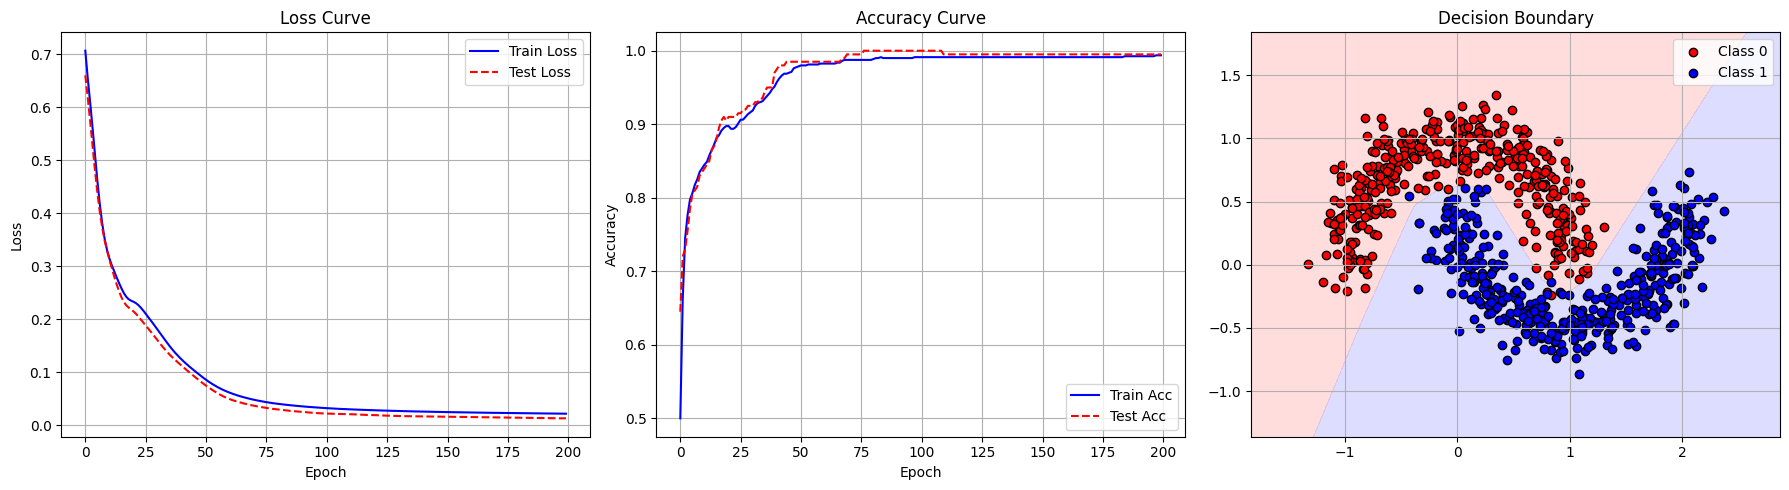

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

%matplotlib inline
plt.figure(figsize=(18, 5))

# --- 1. 绘制损失曲线 ---
plt.subplot(1, 3, 1)
plt.plot(train_losses, label='Train Loss', color='blue')
plt.plot(test_losses, label='Test Loss', color='red', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()
plt.grid(True)

# --- 2. 绘制准确率曲线 ---
plt.subplot(1, 3, 2)
plt.plot(train_accs, label='Train Acc', color='blue')
plt.plot(test_accs, label='Test Acc', color='red', linestyle='--')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Curve')
plt.legend()
plt.grid(True)

# --- 3. 绘制决策边界图 ---
plt.subplot(1, 3, 3)
# 确定网格范围（比数据范围稍微大一点）
x_min, x_max = X_train[:, 0].min() - 0.5, X_train[:, 0].max() + 0.5
y_min, y_max = X_train[:, 1].min() - 0.5, X_train[:, 1].max() + 0.5
#X_train[:, 0]：取所有样本的第一个特，也就是x坐标
#0.5：边距
# 生成密集的网格点
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))
#np.arange(x_min, x_max, 0.01)：从最左边到最右边，每隔 0.01 画一个刻度。
#np.meshgrid(...)：它的作用是把 X 轴和 Y 轴的刻度交叉组合，铺满整个二维平面。
#如果x、y各含两个元素，x坐标复制两行，y坐标复制两列，组合成四个坐标点

# 将网格点展平喂给模型预测
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
#xx.ravel() 和 yy.ravel()：ravel() 是“展平”的意思。
# 把刚才那张 2D 的网格矩阵，拉平成一维的长串（比如把 100x100 的矩阵拉成 10000 个数字的一维数组）。
#np.c_[...]：将拉平之后的x、y坐标按列拼在一起，形成（10000，2）的二维矩阵
#强制转换为张量
model.eval()#非训练模式
with torch.no_grad():
    probs = model(grid).numpy().reshape(xx.shape)
    #model(grid)：模型生成预测概率
    #numpy().reshape(xx.shape)：重新变回与xx性转一样的numpy数组

# 绘制背景等高线 (0到0.5是浅红，0.5到1是浅蓝)
plt.contourf(xx, yy, probs, levels=[0, 0.5, 1], alpha=0.4, colors=['#FFAAAA', '#AAAAFF'])
#plt.contourf：等值线填充，把数值相同的部分涂成一样的颜色

# 把真实的散点画在背景上
plt.scatter(X_train[y_train == 0][:, 0], X_train[y_train == 0][:, 1], 
            c='red', label='Class 0', edgecolors='k')
plt.scatter(X_train[y_train == 1][:, 0], X_train[y_train == 1][:, 1], 
            c='blue', label='Class 1', edgecolors='k')
#edgecolors='k'：给每个圆点加上黑色的边框（k 代表 black）

plt.title('Decision Boundary')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()